# [RQ_2 · HỖ TRỢ] V1 · Dự đoán theo thời gian

Dự đoán lưu lượng xe mỗi giờ từ **giờ trong ngày và thứ trong tuần**. V1 dùng cùng hàm chuẩn bị dữ liệu, mô hình, tuning và đánh giá với V2–V4. Train dùng để fit và chia fold. Validation dùng để đối chiếu. Test giữ riêng cho đánh giá cuối.

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


## 1.1 · Chuẩn bị dữ liệu

### 1.1.1 · Thiết lập môi trường

In [2]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd

cwd = Path.cwd().resolve()
project_dir = next(p for p in (cwd, *cwd.parents)
                   if (p / "data/Metro_Interstate_Traffic_Volume.csv").is_file())
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.data import DATA_PATH as data_path, load_raw
from src.data_validation import validate_structure_and_time
from src.evaluation import regression_metrics, run_observations, weekday_hour_baseline
from src.experiment_logger import save_experiment_log
from src.features import V1_FEATURES, add_time_features
from src.models import MODEL_NAMES, input_columns, results_table
from src.tuning import describe_folds, run_config, summarize_search

### 1.1.2 · Đọc và kiểm tra CSV gốc

In [3]:
raw = load_raw(data_path)
quality = validate_structure_and_time(raw)
display(pd.Series(quality, name="Kiểm tra CSV"))
display(raw.head(3))

row_count                                    48204
column_count                                     9
unique_timestamp_count                       40575
conflicting_timestamp_count                      0
start_time                     2012-10-02 09:00:00
end_time                       2018-09-30 23:00:00
is_time_sorted                                True
Name: Kiểm tra CSV, dtype: object

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767


### 1.1.3 · Gộp mục tiêu theo giờ và chia 70/15/15

In [4]:
from src.experiment_data import load_experiment_splits
splits = load_experiment_splits(stage="processed", include_test=True)
assert sum(map(len, splits.values())) == quality["unique_timestamp_count"]
assert tuple(map(len, splits.values())) == (28402, 6086, 6087)
assert splits["train"]["date_time"].max() < splits["validation"]["date_time"].min()
assert splits["validation"]["date_time"].max() < splits["test"]["date_time"].min()
display(pd.DataFrame({
    name: {"Số giờ": len(part), "Bắt đầu": part["date_time"].min(), "Kết thúc": part["date_time"].max()}
    for name, part in splits.items()
}).T)

,Số giờ,Bắt đầu,Kết thúc
train,28402,2012-10-02 09:00:00,2017-05-10 04:00:00
validation,6086,2017-05-10 05:00:00,2018-01-19 14:00:00
test,6087,2018-01-19 15:00:00,2018-09-30 23:00:00


### 1.1.4 · Tạo đặc trưng thời gian

V1 dùng thông tin giờ và thứ. Ridge biểu diễn hai thông tin đó bằng one-hot của cặp thứ–giờ.

In [5]:
train = add_time_features(splits["train"])
validation = add_time_features(splits["validation"])
display(train[["date_time", *V1_FEATURES, "traffic_volume"]].head())

,date_time,hour,day_of_week,traffic_volume
0,2012-10-02 09:00:00,9,1,5545
1,2012-10-02 10:00:00,10,1,4516
2,2012-10-02 11:00:00,11,1,4767
3,2012-10-02 12:00:00,12,1,5026
4,2012-10-02 13:00:00,13,1,4918


## 1.2 · Baseline trung bình theo thứ–giờ

### 1.2.1 · Kiểm tra số mẫu của từng nhóm

In [6]:
weekday_hour = train.groupby(["day_of_week", "hour"])["traffic_volume"].agg(
    so_mau="size", luu_luong_trung_binh="mean"
)
print(f"{len(weekday_hour)}/168 nhóm; từ {weekday_hour.so_mau.min()} đến {weekday_hour.so_mau.max()} mẫu mỗi nhóm.")
display(weekday_hour.nsmallest(5, "so_mau"))

168/168 nhóm; từ 155 đến 183 mẫu mỗi nhóm.


,,so_mau,luu_luong_trung_binh
day_of_week,hour,,
2,9,155,5029.929032
1,7,156,6150.032051
2,17,159,6048.729560
1,5,160,2725.468750
2,7,160,6173.375000


### 1.2.2 · Dự đoán và đánh giá baseline

In [7]:
baseline_predictions = weekday_hour_baseline(train, validation)
baseline_metrics = regression_metrics(validation["traffic_volume"], baseline_predictions)
display(pd.Series(baseline_metrics, name="Baseline thứ–giờ").round(3))

MAE     285.027
RMSE    501.407
R2        0.935
Name: Baseline thứ–giờ, dtype: float64

## 1.3 · Thí nghiệm và tuning

### 1.3.1 · Kiểm tra đầu vào và mốc các fold

In [8]:
for name in MODEL_NAMES:
    columns = input_columns(name, V1_FEATURES)
    assert "traffic_volume" not in columns
    for frame in (train, validation):
        assert set(columns) <= set(frame)
        assert np.isfinite(frame[columns].to_numpy(dtype=float)).all()
    print(f"{name}: {', '.join(columns)}")
display(describe_folds(train))

Linear Regression: hour, day_of_week
Random Forest: hour, day_of_week
Gradient Boosting: hour, day_of_week
MLP: hour, day_of_week
Ridge: weekday_hour
XGBoost: hour, day_of_week


,fold,fit_start,fit_end,validation_start,validation_end,n_fit,n_validation
0,1,2012-10-02 09:00:00,2013-08-18 18:00:00,2013-08-18 19:00:00,2015-07-07 11:00:00,7102,7100
1,2,2012-10-02 09:00:00,2015-07-07 11:00:00,2015-07-07 12:00:00,2016-07-15 04:00:00,14202,7100
2,3,2012-10-02 09:00:00,2016-07-15 04:00:00,2016-07-15 05:00:00,2017-05-10 04:00:00,21302,7100


### 1.3.2 · Chạy từng mô hình

LR là mốc tuyến tính với một cấu hình. Các mô hình còn lại chọn tham số theo MAE trung bình của ba fold trong train. Điểm validation được tính sau khi fit lại trên toàn train.

#### 1.3.2.1 · Linear Regression

In [9]:
linear, = run_config("T0_thu_gio", V1_FEATURES, train, validation, ["Linear Regression"])
display(summarize_search(linear["search"]).head(3).round(3))

,parameters,fold_1_mae,fold_2_mae,fold_3_mae,mean_cv_mae,rank
0,{},1623.531,1634.262,1577.327,1611.706,1


#### 1.3.2.2 · Random Forest

In [10]:
forest, = run_config("T0_thu_gio", V1_FEATURES, train, validation, ["Random Forest"])
display(summarize_search(forest["search"]).head(3).round(3))

,parameters,fold_1_mae,fold_2_mae,fold_3_mae,mean_cv_mae,rank
0,"{'min_samples_leaf': 1, 'max_features': 0.5, '...",316.683,286.208,306.835,303.242,1
1,"{'min_samples_leaf': 5, 'max_features': 0.33, ...",316.683,286.208,306.835,303.242,1
2,"{'min_samples_leaf': 10, 'max_features': 0.5, ...",316.683,286.208,306.835,303.242,1


#### 1.3.2.3 · Gradient Boosting

In [11]:
boost, = run_config("T0_thu_gio", V1_FEATURES, train, validation, ["Gradient Boosting"])
display(summarize_search(boost["search"]).head(3).round(3))

,parameters,fold_1_mae,fold_2_mae,fold_3_mae,mean_cv_mae,rank
0,"{'model__n_estimators': 200, 'model__max_depth...",328.710,299.919,319.853,316.161,1
1,"{'model__n_estimators': 200, 'model__max_depth...",431.775,408.083,435.596,425.151,2
2,"{'model__n_estimators': 100, 'model__max_depth...",484.067,453.498,471.603,469.723,3


#### 1.3.2.4 · MLP

In [12]:
mlp, = run_config("T0_thu_gio", V1_FEATURES, train, validation, ["MLP"])
display(summarize_search(mlp["search"]).head(3).round(3))

e:\Project\SGU_HocMay_2026-2027\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
e:\Project\SGU_HocMay_2026-2027\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
e:\Project\SGU_HocMay_2026-2027\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,parameters,fold_1_mae,fold_2_mae,fold_3_mae,mean_cv_mae,rank
0,"{'model__learning_rate_init': 0.001, 'model__h...",797.084,535.681,1577.606,970.124,1
1,"{'model__learning_rate_init': 0.003, 'model__h...",1624.206,1634.352,828.215,1362.257,2
2,"{'model__learning_rate_init': 0.001, 'model__h...",1624.337,1635.407,1577.408,1612.384,3


#### 1.3.2.5 · Ridge

In [13]:
ridge, = run_config("T0_thu_gio", V1_FEATURES, train, validation, ["Ridge"])
display(summarize_search(ridge["search"]).head(3).round(3))

,parameters,fold_1_mae,fold_2_mae,fold_3_mae,mean_cv_mae,rank
0,{'model__alpha': 0.1},317.329,286.356,306.885,303.523,1
1,{'model__alpha': 1.0},327.407,288.955,306.810,307.724,2
2,{'model__alpha': 10.0},509.036,373.088,335.709,405.944,3


#### 1.3.2.6 · XGBoost

In [14]:
xgb, = run_config("T0_thu_gio", V1_FEATURES, train, validation, ["XGBoost"])
display(summarize_search(xgb["search"]).head(3).round(3))

,parameters,fold_1_mae,fold_2_mae,fold_3_mae,mean_cv_mae,rank
0,"{'subsample': 1.0, 'min_child_weight': 5, 'max...",316.628,286.173,306.945,303.249,1
1,"{'subsample': 0.7, 'min_child_weight': 5, 'max...",319.290,288.836,309.534,305.887,2
2,"{'subsample': 1.0, 'min_child_weight': 10, 'ma...",592.513,567.021,583.838,581.124,3


### 1.3.3 · So sánh trên cùng các giờ validation

In [15]:
results = [linear, forest, boost, mlp, ridge, xgb]
baseline_row = {"model": "Trung bình thứ–giờ", **baseline_metrics}
comparison = pd.concat([pd.DataFrame([baseline_row]), results_table(results)], ignore_index=True)
display(comparison.sort_values("MAE").round(3))

,model,MAE,RMSE,R2,config,so_dac_trung,mean_cv_mae
6,XGBoost,284.973,501.420,0.935,T0_thu_gio,2.0,303.249
0,Trung bình thứ–giờ,285.027,501.407,0.935,NaN,NaN,NaN
2,Random Forest,285.113,501.423,0.935,T0_thu_gio,2.0,303.242
5,Ridge,285.134,501.371,0.935,T0_thu_gio,2.0,303.523
3,Gradient Boosting,299.909,513.990,0.932,T0_thu_gio,2.0,316.161
4,MLP,417.475,617.723,0.901,T0_thu_gio,2.0,970.124
1,Linear Regression,1602.862,1811.508,0.151,T0_thu_gio,2.0,1611.706


### 1.3.4 · So sánh đường dự đoán trên validation

Mỗi ô so một mô hình với **lưu lượng thực tế** và **baseline trung bình thứ–giờ**. Các ô dùng cùng 7 ngày đầu validation và cùng thang đo. Đường bị ngắt tại các giờ thiếu bản ghi. MAE trong tiêu đề chỉ tính trên đoạn đang xem. Bảng trên báo điểm của toàn bộ validation.

In [16]:
curves = validation.set_index("date_time")[["traffic_volume"]].rename(
    columns={"traffic_volume": "Thực tế"}
)
curves["Baseline thứ–giờ"] = baseline_predictions
for item in results:
    curves[item["model"]] = item["prediction"]

start = curves.index.min()
week_hours = pd.date_range(start, periods=7 * 24, freq="h")
week = curves.reindex(week_hours)
print(f"Đoạn minh họa: {len(week) - week['Thực tế'].isna().sum()}/{len(week)} giờ có quan sát.")

Đoạn minh họa: 168/168 giờ có quan sát.


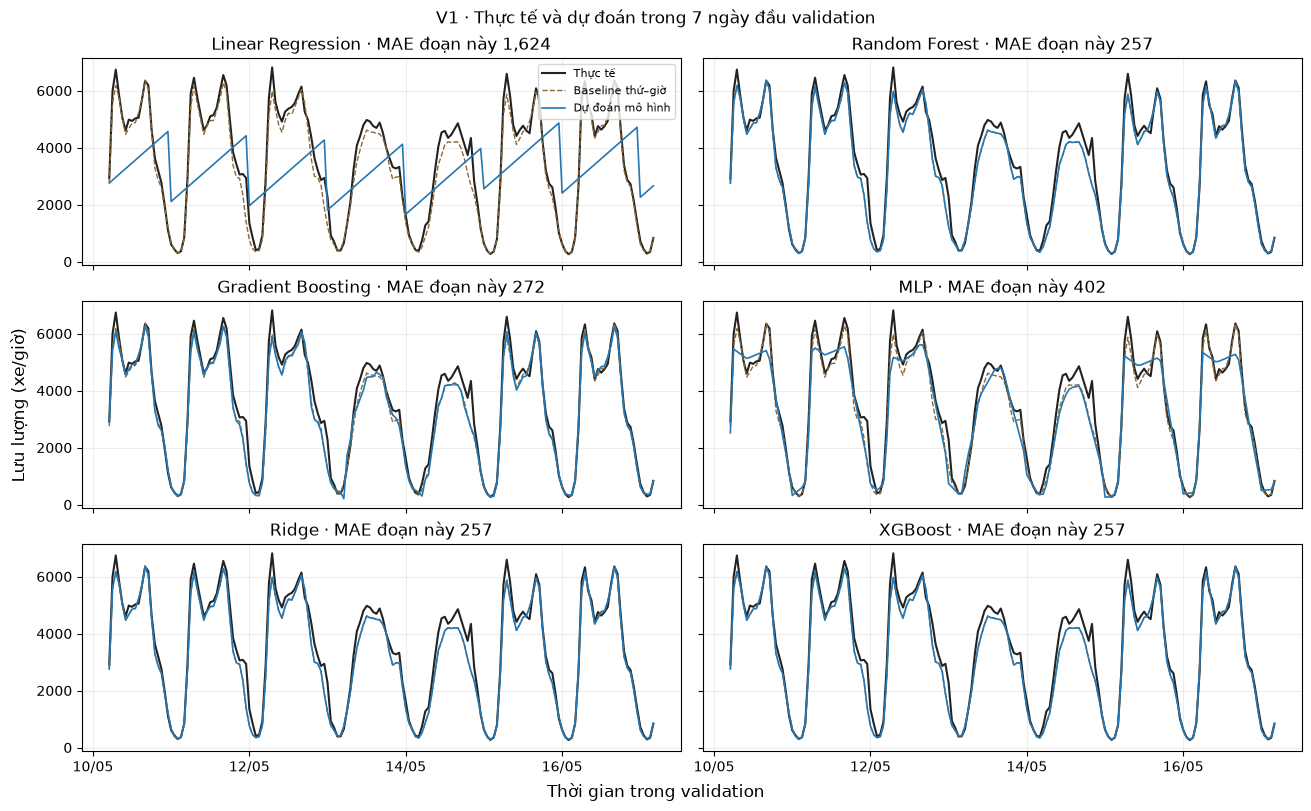

In [17]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(13, 8), sharex=True, sharey=True, layout="constrained")
for ax, item in zip(axes.flat, results):
    name = item["model"]
    segment_mae = (week[name] - week["Thực tế"]).abs().mean()
    ax.plot(week.index, week["Thực tế"], color="#222222", linewidth=1.5, label="Thực tế")
    ax.plot(week.index, week["Baseline thứ–giờ"], "--", color="#8a6837", linewidth=1, label="Baseline thứ–giờ")
    ax.plot(week.index, week[name], color="#2477b3", linewidth=1.2, label="Dự đoán mô hình")
    ax.set_title(f"{name} · MAE đoạn này {segment_mae:,.0f}")
    ax.grid(alpha=0.22)

axes[0, 0].legend(loc="upper right", fontsize=8)
axes[-1, 0].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.supxlabel("Thời gian trong validation")
fig.supylabel("Lưu lượng (xe/giờ)")
fig.suptitle("V1 · Thực tế và dự đoán trong 7 ngày đầu validation")
if os.environ.get("SAVE_EXPERIMENT_RESULTS") == "1":
    figure_dir = project_dir / "outputs" / "fold_safe" / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_dir / "V_1_validation_curves.png", dpi=160)
plt.show()

## 1.4 · Lưu kết quả và ghi nhật ký

### 1.4.1 · Lưu kết quả V1 vào Excel

Chạy cell này sau khi đã có kết quả của sáu mô hình và baseline thứ–giờ. Khi cell in «Đã lưu V1», kiểm tra dòng V1 trong sheet **Tổng quan**. Nếu Excel đang mở, đóng workbook rồi chạy lại riêng cell lưu.

Ảnh PNG là tùy chọn qua `SAVE_EXPERIMENT_RESULTS=1`. Nhật ký TXT bên dưới là tùy chọn qua `SAVE_EXPERIMENT_LOGS=1`.

In [18]:
from importlib import reload
import src.experiment_excel as excel_io

workbook_path = reload(excel_io).save_experiment_workbook(
    version="V_1", results=results, target=validation, splits=splits,
    folds={"T0_thu_gio": describe_folds(train)},
    data_path=data_path, output_dir=project_dir / "experiments",
    baseline_metrics=baseline_metrics, baseline_predictions=baseline_predictions,
)
print("Đã lưu V1:", workbook_path)

Đã lưu V1: E:\Project\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\experiments\experiments_logs.xlsx


In [19]:
if os.environ.get("SAVE_EXPERIMENT_LOGS") == "1":
    observations = run_observations(data_path, splits, "notebooks/experiments/V_1.ipynb")
    for item in results:
        search = item["search"]
        save_experiment_log(
            model=f"V1 - {item['model']}", features=item["features"], results=item["metrics"],
            observations=observations + [
                f"Tham số: {search.best_params_}",
                summarize_search(search).to_json(orient="records", force_ascii=False),
            ],
            problems=["Dữ liệu thiếu giờ; điểm chỉ tính trên các giờ validation có quan sát."],
            next_steps=["So sánh V1 với cấu hình có ngày lễ ở V2."],
        )

## 1.5 · Bảng đối chiếu lịch sử

Bảng dưới lấy từ lần chạy trước khi V1 chuyển sang hàm dùng chung. Cách biểu diễn và phạm vi tham số đã thay đổi. Chạy lại mục 1.3 để có kết quả theo cấu hình mới.

Bước tiếp theo là [V2 · Thời gian và ngày lễ](V_2.ipynb).

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>MAE</th>
      <th>RMSE</th>
      <th>R2</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>MLP</th>
      <td>283.320141</td>
      <td>504.034571</td>
      <td>0.934254</td>
    </tr>
    <tr>
      <th>Random Forest</th>
      <td>284.848654</td>
      <td>501.577887</td>
      <td>0.934893</td>
    </tr>
    <tr>
      <th>Trung bình thứ–giờ</th>
      <td>285.027201</td>
      <td>501.407163</td>
      <td>0.934937</td>
    </tr>
    <tr>
      <th>Gradient Boosting</th>
      <td>351.121119</td>
      <td>557.038548</td>
      <td>0.919699</td>
    </tr>
    <tr>
      <th>Linear Regression</th>
      <td>581.907324</td>
      <td>807.956640</td>
      <td>0.831062</td>
    </tr>
    <tr>
      <th>Ridge</th>
      <td>581.941398</td>
      <td>807.954197</td>
      <td>0.831063</td>
    </tr>
  </tbody>
</table>
</div>

Trạng thái: đang thử nghiệm.

<!-- proposal-assessment -->
## Đánh giá đối với proposal — RQ_2

**Vai trò: HỖ TRỢ.** Mã đối chiếu: [E32](../../docs/experiment_tracking/EXPERIMENTS_BY_DATE_AND_RQ.md). 

- **Câu hỏi:** Giờ–thứ và baseline thống kê tạo mốc dự đoán nào?
- **Đánh giá:** Tạo mốc A2 (giờ–thứ) và baseline thứ–giờ để sàng lọc mô hình. RF RMSE 501,423 gần baseline 501,407; chưa có bằng chứng RF vượt baseline rõ rệt trong nhánh tối giản này.
- **Giới hạn kết luận:** Không phải đối chứng chỉ bỏ ngày lễ khỏi A12; ngày chạy còn mâu thuẫn giữa tên thư mục và notebook. Không xếp hạng chung với A17/A12 khi chưa khớp protocol.
- **Bằng chứng:** [E32: ConfigA_comparison_from_notebook.xlsx](ConfigA_comparison_from_notebook.xlsx).

Đánh giá trên dựa vào hiện vật lịch sử đã đối chứng, không phải kết quả chạy mới. Code lấy dữ liệu đã được chuẩn hóa; chưa huấn luyện lại hoặc chấm test.
